# Trajectory Visualization and Analysis
Visualizes study characteristics from movement data in mbr_studies_2year/

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import glob
import os

%matplotlib inline

In [11]:
# Load the first study from mbr_studies_2year/
output_dir = 'mbr_studies_2year'
files = sorted(glob.glob(os.path.join(output_dir, '*_2year.csv')))


first_file = files[1]
df = pd.read_csv(first_file)
print(f"Data shape: {df.shape}")
print(f"Columns: {list(df.columns)}")

Data shape: (83100, 10)
Columns: ['event-id', 'visible', 'timestamp', 'location-long', 'location-lat', 'sensor-type', 'individual-taxon-canonical-name', 'tag-local-identifier', 'individual-local-identifier', 'study-name']


In [12]:
# Print study metadata
print("="*60)
print("STUDY METADATA")
print("="*60)

# Extract study ID from filename
study_id = os.path.basename(first_file).split('_')[0]
print(f"Study ID: {study_id}")
print(f"Filename: {os.path.basename(first_file)}")

# Get species information
if 'individual-taxon-canonical-name' in df.columns:
    species = df['individual-taxon-canonical-name'].unique()
    print(f"Species: {', '.join(species)}")
else:
    print("Species information not available in individual-taxon-canonical-name column")
    print(f"Available columns: {list(df.columns)}")

# Basic counts
num_individuals = df['individual-local-identifier'].nunique()
num_points = len(df)

print(f"Number of individuals: {num_individuals:,}")
print(f"Number of data points: {num_points:,}")
print(f"Average points per individual: {num_points/num_individuals:.1f}")

# Time range
if 'timestamp' in df.columns:
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    print(f"Time range: {df['timestamp'].min()} to {df['timestamp'].max()}")
    duration = df['timestamp'].max() - df['timestamp'].min()
    print(f"Duration: {duration.days} days")

STUDY METADATA
Study ID: 0b812dab-840b-4940-af5d-98cf2c5f9f63
Filename: 0b812dab-840b-4940-af5d-98cf2c5f9f63_Beck_0b812dab_2year.csv
Species: Antilocapra americana
Number of individuals: 20
Number of data points: 83,100
Average points per individual: 4155.0
Time range: 2017-11-14 06:03:00 to 2019-11-07 21:03:00
Duration: 723 days


In [13]:
# compute and filter by time gap
df = df.sort_values(['individual-local-identifier', 'timestamp'])
df['time_since_last'] = df.groupby('individual-local-identifier')['timestamp'].diff()

gap_q = 0.999
per_indiv_cutoff = (
    df.groupby('individual-local-identifier')['time_since_last']
      .transform(lambda s: s.dropna().quantile(gap_q))
)
print("time cutoffs", per_indiv_cutoff.unique())

df_filtered = df[
    df['time_since_last'].notna() & 
    (df['time_since_last'] <= per_indiv_cutoff)
]

df_filtered.head()

time cutoffs <TimedeltaArray>
['0 days 08:00:00', '0 days 12:00:00', '0 days 08:00:42.060000']
Length: 3, dtype: timedelta64[ns]


,event-id,visible,timestamp,location-long,location-lat,sensor-type,individual-taxon-canonical-name,tag-local-identifier,individual-local-identifier,study-name,time_since_last
1,24727682023,True,2017-11-14 13:02:00,-108.489137,41.190210,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 03:59:00
2,24727682024,True,2017-11-14 17:03:00,-108.490213,41.193330,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:01:00
3,24727682025,True,2017-11-14 21:02:00,-108.461818,41.190143,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 03:59:00
4,24727682026,True,2017-11-15 01:03:00,-108.463145,41.198393,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:01:00
5,24727682027,True,2017-11-15 05:03:00,-108.463337,41.195990,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:00:00


In [14]:
# compute and filter by step length
lat = np.radians(df_filtered['location-lat'])
lon = np.radians(df_filtered['location-long'])

# cool trick for grouped diffs
lat1 = lat.groupby(df_filtered['individual-local-identifier']).shift()
lon1 = lon.groupby(df_filtered['individual-local-identifier']).shift()
dlat = lat - lat1
dlon = lon - lon1

a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat) * np.sin(dlon/2)**2
c = 2 * np.arcsin(np.sqrt(a))

R = 6371000  # meters
df_filtered['step_length'] = R * c

step_q = 0.95
step_multiplier = 2

q_vals = df_filtered.groupby('individual-local-identifier')['step_length'] \
                    .transform(lambda s: s.quantile(step_q))
print("Step length cutoffs", q_vals.unique())

df_filtered2 = df_filtered[df_filtered['step_length'] <= step_multiplier*q_vals]
df_filtered2.head()

Step length cutoffs [2104.23039949 2194.90252218 1982.90250184 1868.95800867 2191.28685802
 2034.64343874 2326.6221156  1766.67333049 1581.41114219 2173.22721198
 2478.43380568 1923.42523081 1965.3279731  2516.57550136 1792.52407063
 2330.22709467 1784.18584176 2011.20010447 1796.30307407 2273.0932938 ]


/tmp/ipykernel_3499381/1280164598.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['step_length'] = R * c


,event-id,visible,timestamp,location-long,location-lat,sensor-type,individual-taxon-canonical-name,tag-local-identifier,individual-local-identifier,study-name,time_since_last,step_length
2,24727682024,True,2017-11-14 17:03:00,-108.490213,41.193330,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:01:00,358.433286
3,24727682025,True,2017-11-14 21:02:00,-108.461818,41.190143,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 03:59:00,2402.236912
4,24727682026,True,2017-11-15 01:03:00,-108.463145,41.198393,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:01:00,924.050148
5,24727682027,True,2017-11-15 05:03:00,-108.463337,41.195990,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:00:00,267.718995
6,24727682028,True,2017-11-15 09:03:00,-108.466223,41.194753,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:00:00,277.926379


In [15]:
# turn angles
df_filtered3 = df_filtered2.sort_values(
    ['individual-local-identifier', 'timestamp']
)

lat = np.radians(df_filtered2['location-lat'])
lon = np.radians(df_filtered2['location-long'])
lat_prev = lat.groupby(df_filtered2['individual-local-identifier']).shift()
lon_prev = lon.groupby(df_filtered2['individual-local-identifier']).shift()
dlon = lon - lon_prev
y = np.sin(dlon) * np.cos(lat)
x = (np.cos(lat_prev) * np.sin(lat) -
     np.sin(lat_prev) * np.cos(lat) * np.cos(dlon))

bearing = np.arctan2(y, x)
bearing_prev = bearing.groupby(df_filtered2['individual-local-identifier']).shift()
raw_turn = bearing - bearing_prev

df_filtered3['turn_angle'] = np.arctan2(
    np.sin(raw_turn),
    np.cos(raw_turn)
)
df_filtered3 = df_filtered3[df_filtered3['turn_angle'].notna()]

df_filtered3.head()

,event-id,visible,timestamp,location-long,location-lat,sensor-type,individual-taxon-canonical-name,tag-local-identifier,individual-local-identifier,study-name,time_since_last,step_length,turn_angle
4,24727682026,True,2017-11-15 01:03:00,-108.463145,41.198393,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:01:00,924.050148,-1.839093
5,24727682027,True,2017-11-15 05:03:00,-108.463337,41.195990,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:00:00,267.718995,-2.961230
6,24727682028,True,2017-11-15 09:03:00,-108.466223,41.194753,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:00:00,277.926379,0.993288
7,24727682029,True,2017-11-15 13:03:00,-108.465782,41.194462,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:00:00,49.163341,-1.903667
8,24727682030,True,2017-11-15 17:03:00,-108.465250,41.192025,gps,Antilocapra americana,15827,p5827,"Pronghorn (Antilocapra americana), Wyoming/Col...",0 days 04:00:00,274.573598,0.687682


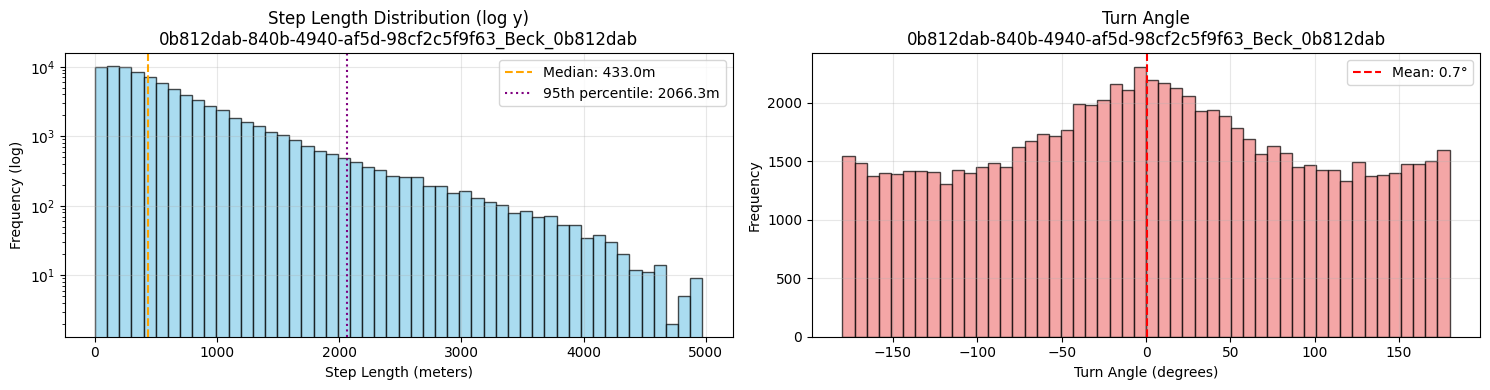

In [16]:
study_name = os.path.basename(first_file).replace('_2year.csv', '')
step_lengths_filtered = df_filtered3.step_length
turn_angles_filtered = df_filtered3.turn_angle

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

ax1.hist(step_lengths_filtered, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
ax1.set_xlabel('Step Length (meters)')
ax1.set_ylabel('Frequency (log)')
ax1.set_title(f'Step Length Distribution (log y)\n{study_name}')
ax1.grid(True, alpha=0.3)

# Add statistics to step length plot
mean_step = np.mean(step_lengths_filtered)
median_step = np.median(step_lengths_filtered)
ax1.axvline(median_step, color='orange', linestyle='--', label=f'Median: {median_step:.1f}m')
ax1.axvline(q_vals.mean(), color='purple', linestyle=':', label=f'{step_q*100:.0f}th percentile: {q_vals.mean():.1f}m')
ax1.legend()
ax1.set_yscale('log')

# Turn angle distribution (filtered data)
turn_angles_filtered_deg = np.degrees(turn_angles_filtered)
ax2.hist(turn_angles_filtered_deg, bins=50, alpha=0.7, color='lightcoral', edgecolor='black')
ax2.set_xlabel('Turn Angle (degrees)')
ax2.set_ylabel('Frequency')
ax2.set_title(f'Turn Angle\n{study_name}')
ax2.grid(True, alpha=0.3)

# Add statistics to turn angle plot
mean_turn = np.mean(turn_angles_filtered_deg)
ax2.axvline(mean_turn, color='red', linestyle='--', label=f'Mean: {mean_turn:.1f}°')
ax2.legend()

plt.tight_layout()
plt.show()

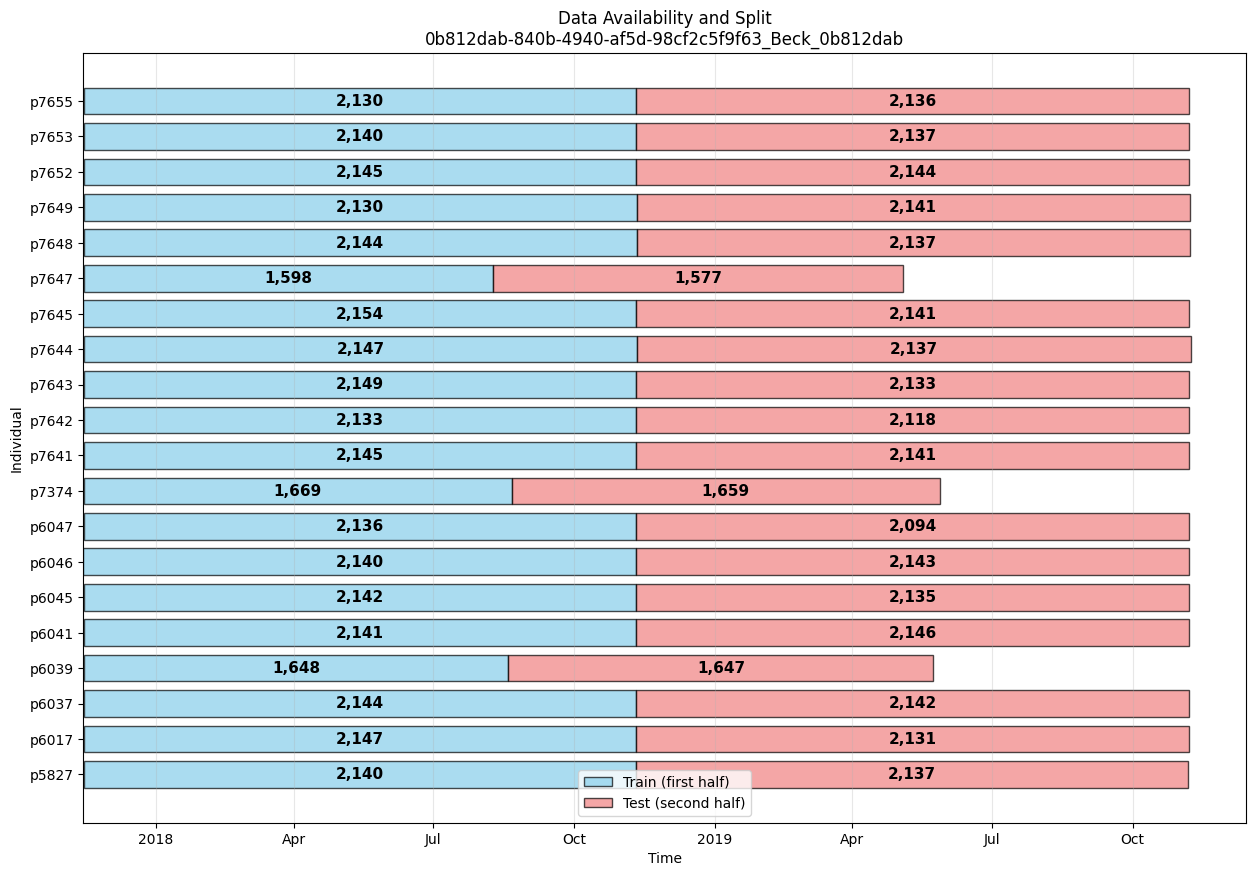

In [17]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from datetime import timedelta

df_timeline = df_filtered2.copy()
df_timeline = df_timeline.sort_values(['individual-local-identifier', 'timestamp'])

gap_threshold = pd.Timedelta(days=3)

# Compute start, end, midpoint
span = (
    df_timeline.groupby('individual-local-identifier')['timestamp']
    .agg(start='min', end='max')
)
span['mid'] = span['start'] + (span['end'] - span['start']) / 2

individuals = span.index.tolist()

fig, ax = plt.subplots(figsize=(15, 0.5 * len(individuals)))
bar_height = 0.75

train_color = 'skyblue'
test_color  = 'lightcoral'

for i, individual in enumerate(individuals):
    ind = df_timeline[df_timeline['individual-local-identifier'] == individual]
    ts = ind['timestamp'].sort_values()
    
    start = span.loc[individual, 'start']
    end   = span.loc[individual, 'end']
    mid   = span.loc[individual, 'mid']

    gaps = ts.diff() > gap_threshold
    segment_id = gaps.cumsum()

    for seg, seg_ts in ts.groupby(segment_id):
        seg_start = seg_ts.min()
        seg_end   = seg_ts.max()
        count_pts = len(seg_ts)

        # --- Format the number with commas ---
        count_lbl = f"{count_pts:,}"

        # Segment entirely before midpoint
        if seg_end <= mid:
            seg_color = train_color

            ax.barh(
                i, seg_end - seg_start, left=seg_start,
                height=bar_height, color=seg_color,
                alpha=0.7, edgecolor='black'
            )

            ax.text(
                seg_start + (seg_end - seg_start)/2,
                i,
                count_lbl,
                ha='center', va='center',
                color='black', fontsize=11, fontweight='bold'
            )

        # Segment entirely after midpoint
        elif seg_start >= mid:
            seg_color = test_color

            ax.barh(
                i, seg_end - seg_start, left=seg_start,
                height=bar_height, color=seg_color,
                alpha=0.7, edgecolor='black'
            )

            ax.text(
                seg_start + (seg_end - seg_start)/2,
                i,
                count_lbl,
                ha='center', va='center',
                color='black', fontsize=11, fontweight='bold'
            )

        else:
            # Segment crosses midpoint → split into two bars
            pts_before_mid = len(seg_ts[seg_ts <= mid])
            pts_after_mid = count_pts - pts_before_mid

            # Labels with commas
            lbl_before = f"{pts_before_mid:,}"
            lbl_after  = f"{pts_after_mid:,}"

            # First half (train)
            ax.barh(
                i, mid - seg_start, left=seg_start,
                height=bar_height, color=train_color,
                alpha=0.7, edgecolor='black'
            )
            ax.text(
                seg_start + (mid - seg_start)/2,
                i,
                lbl_before,
                ha='center', va='center',
                color='black', fontsize=11, fontweight='bold'
            )

            # Second half (test)
            ax.barh(
                i, seg_end - mid, left=mid,
                height=bar_height, color=test_color,
                alpha=0.7, edgecolor='black'
            )
            ax.text(
                mid + (seg_end - mid)/2,
                i,
                lbl_after,
                ha='center', va='center',
                color='black', fontsize=11, fontweight='bold'
            )

ax.set_yticks(range(len(individuals)))
ax.set_yticklabels(individuals)

# date axis
locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(formatter)

ax.set_xlabel("Time")
ax.set_ylabel("Individual")
ax.set_title(f"Data Availability and Split\n{study_name}")

ax.grid(True, axis='x', alpha=0.3)

legend_patches = [
    Patch(facecolor=train_color, edgecolor='black', alpha=0.7, label='Train (first half)'),
    Patch(facecolor=test_color,  edgecolor='black', alpha=0.7, label='Test (second half)')
]
ax.legend(handles=legend_patches, loc='lower center')

# plt.tight_layout()
plt.show()


/tmp/ipykernel_3499381/3937869336.py:48: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20', len(individuals))


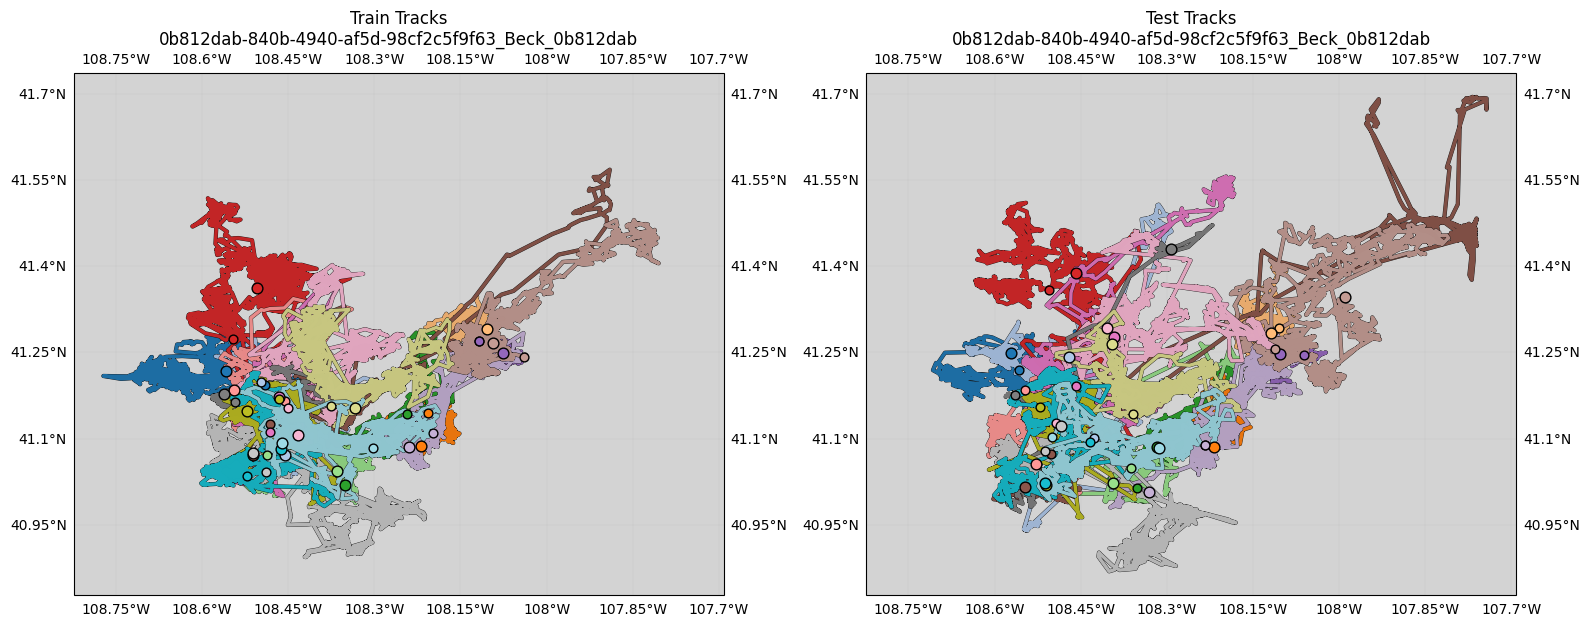

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Start from your cleaned dataframe
df_tracks = df_filtered2.copy()
df_tracks = df_tracks.sort_values(['individual-local-identifier', 'timestamp'])

# --- 1. Compute per-individual midpoint between first and last measurement ---
span = (
    df_tracks.groupby('individual-local-identifier')['timestamp']
    .agg(start='min', end='max')
)
span['mid'] = span['start'] + (span['end'] - span['start']) / 2

# Map midpoint back onto each row
df_tracks['mid_time'] = df_tracks['individual-local-identifier'].map(span['mid'])

# --- 2. Flag train vs test points ---
df_tracks['set'] = np.where(
    df_tracks['timestamp'] <= df_tracks['mid_time'],
    'train',
    'test'
)

# --- 3. Common spatial extent (for both maps) ---
lat_min = df_tracks['location-lat'].min()
lat_max = df_tracks['location-lat'].max()
lon_min = df_tracks['location-long'].min()
lon_max = df_tracks['location-long'].max()

lat_pad = (lat_max - lat_min) * 0.05 if lat_max > lat_min else 0.01
lon_pad = (lon_max - lon_min) * 0.05 if lon_max > lon_min else 0.01

lat_min -= lat_pad
lat_max += lat_pad
lon_min -= lon_pad
lon_max += lon_pad

# --- 4. Color map: one color per individual ---
individuals = df_tracks['individual-local-identifier'].unique()
cmap = cm.get_cmap('tab20', len(individuals))
color_map = {ind: cmap(i) for i, ind in enumerate(individuals)}

# --- 5. Create side-by-side map plots with Cartopy ---
proj = ccrs.PlateCarree()

fig, (ax_train, ax_test) = plt.subplots(
    1, 2, figsize=(16, 7),
    subplot_kw={'projection': proj}
)

def setup_map_axis(ax, title):
    ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=proj)
    ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=0)
    ax.add_feature(cfeature.OCEAN, facecolor='lightblue', zorder=0)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax.gridlines(draw_labels=True, linewidth=0.2, alpha=0.5)
    ax.set_title(f"{title}\n{study_name}", fontsize=12)

def plot_tracks(ax, subset_df):
    for indiv, ind_df in subset_df.groupby('individual-local-identifier'):
        ind_df = ind_df.sort_values('timestamp')
        if len(ind_df) < 2:
            continue

        col = color_map[indiv]

        ax.plot(
            ind_df['location-long'].values,
            ind_df['location-lat'].values,
            '-', linewidth=3, alpha=0.9,   # ← black border
            color='black', transform=proj, 
        )

        ax.plot(
            ind_df['location-long'].values,
            ind_df['location-lat'].values,
            '-', linewidth=2.5, alpha=0.9,   # ← thicker
            color=col, transform=proj, 
        )
        

        # Larger start point (was s=15)
        ax.scatter(
            ind_df['location-long'].iloc[0],
            ind_df['location-lat'].iloc[0],
            s=40, color=col, edgecolor='black',   # ← bigger
            transform=proj, zorder=3
        )

        # Larger end point (was s=25)
        ax.scatter(
            ind_df['location-long'].iloc[-1],
            ind_df['location-lat'].iloc[-1],
            s=60, facecolor=col, edgecolor='black',  # ← bigger
            transform=proj, zorder=3
        )


# Prepare subsets
train_df = df_tracks[df_tracks['set'] == 'train']
test_df  = df_tracks[df_tracks['set'] == 'test']

# Left: train
setup_map_axis(ax_train, "Train Tracks")
plot_tracks(ax_train, train_df)

# Right: test
setup_map_axis(ax_test, "Test Tracks")
plot_tracks(ax_test, test_df)

# --- 6. Legend for individuals (may get big if many animals) ---
legend_handles = [
    Patch(color=color_map[ind], label=str(ind)) for ind in individuals
]
# You can limit legend size if needed:
# legend_handles = legend_handles[:20]

# fig.legend(
#     handles=legend_handles,
#     title="Individuals",
#     loc='upper center',
#     ncol=min(len(legend_handles), 6),
#     fontsize=8
# )

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()
